In [4]:
import pandas as pd
df = pd.read_csv("results-sorted.csv")
df.set_index("date", inplace=True)

In [15]:
df.columns

Index(['simulator', 'algorithm', 'n_qubits', 'command', 'mean', 'stddev',
       'median', 'user', 'system', 'min', 'max'],
      dtype='object')

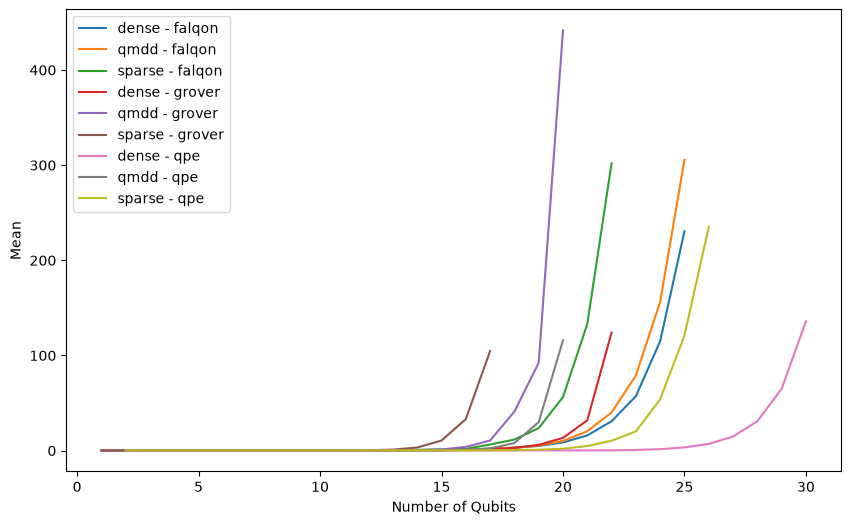

In [21]:
# Plot curves grouping by "simulator" and "algorithm" columns, with "n_qubits" as x-axis and "mean" as the y-axis.
# df.groupby(["simulator", "algorithm"]).plot(x="n_qubits", y="mean", legend=True)

# Plot all curves in a single plot, with "n_qubits" as x-axis and "mean" as the y-axis, and different colors for each curve.
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
for (algorithm, simulator), group in df.groupby(["algorithm", "simulator"]):
    plt.plot(group["n_qubits"], group["mean"], label=f"{simulator} - {algorithm}")
plt.xlabel("Number of Qubits")
plt.ylabel("Mean")
plt.legend()

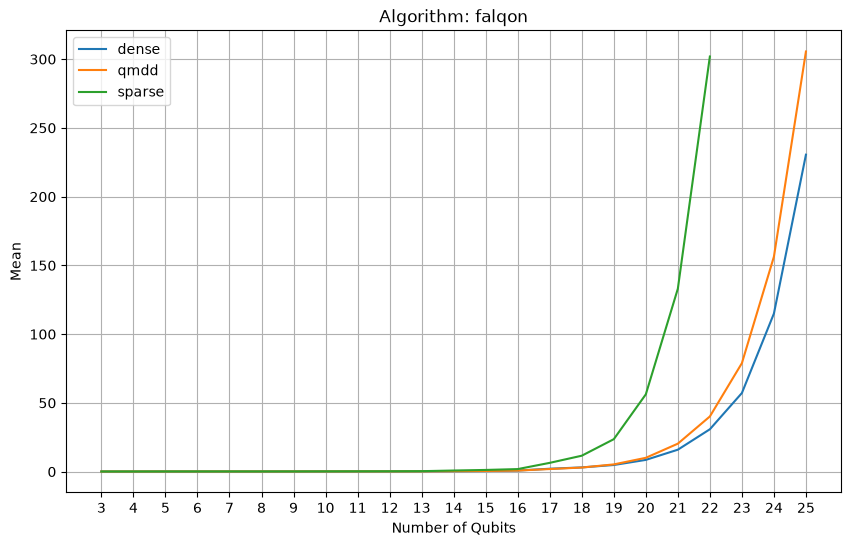

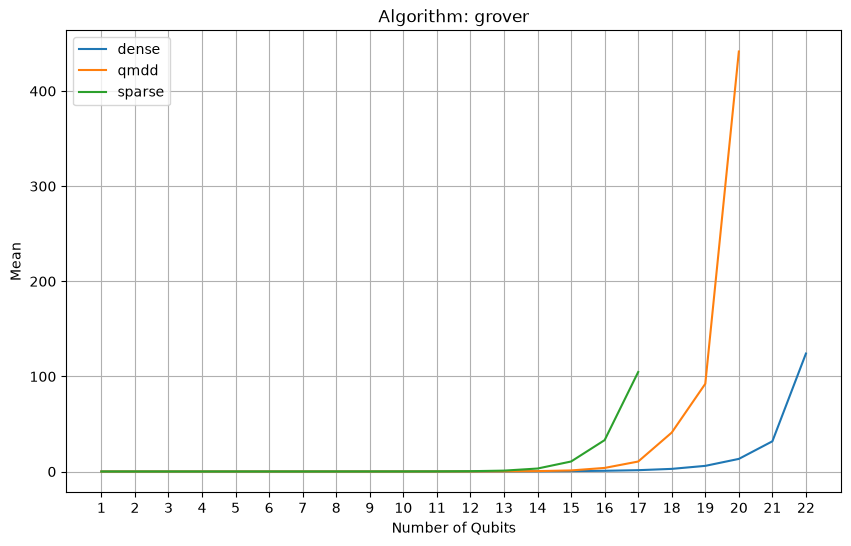

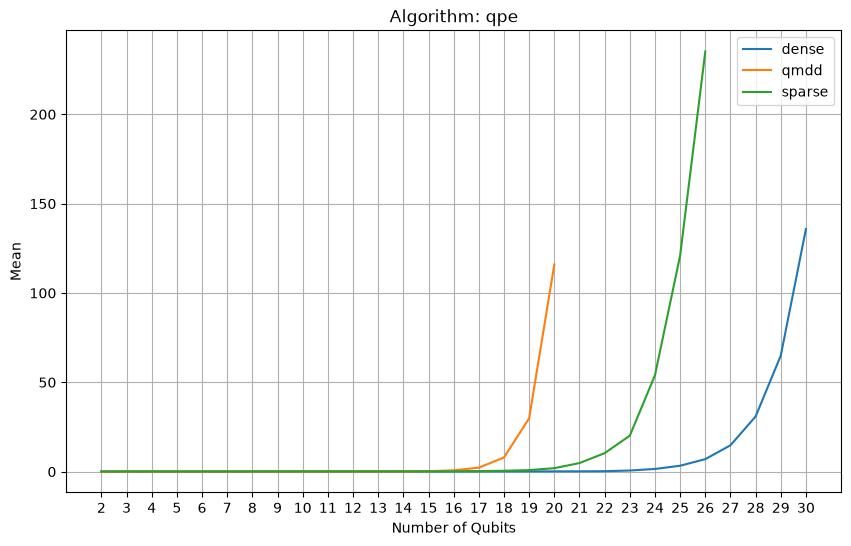

In [24]:
# Make a different plot for each algorithm, comparing simulators, with "n_qubits" as x-axis and "mean" as the y-axis.
for algorithm, group in df.groupby("algorithm"):
    plt.figure(figsize=(10, 6))
    for simulator, sub_group in group.groupby("simulator"):
        plt.plot(sub_group["n_qubits"], sub_group["mean"], label=simulator)
    plt.title(f"Algorithm: {algorithm}")
    plt.xlabel("Number of Qubits")
    plt.xticks(group["n_qubits"].unique())
    plt.grid()
    plt.ylabel("Mean")
    plt.legend()
    plt.show()